# Customer Behavior Analysis & Online Food Ordering Prediction
### Portfolio Project | Python · Pandas · Seaborn · Scikit-learn

## Business problem
Explore the characteristics and feedback of customers in an online food-ordering dataset, identify useful patterns, and evaluate whether customer attributes can help predict the `Output` field.

## Important limitations
- This dataset contains only 388 records, so findings may not generalize to a wider population.
- `Output` must be interpreted using the dataset documentation or domain context before drawing business conclusions.
- This is observational data: associations do not prove causation.
- The dataset includes `Unnamed: 13`, which appears to duplicate `Output`. We check this and remove the duplicate to avoid leakage.

## 1. Imports and setup

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme()

DATA_PATH = Path("online food delivery dataset.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../online food delivery dataset.csv")

df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {df_raw.shape[0]}, columns: {df_raw.shape[1]}")
display(df_raw.head())

Rows: 388, columns: 14


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


## 2. Data understanding and quality checks
Review column names, data types, missing values, duplicates, and category values before analysis.

In [3]:
quality = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "unique_values": df_raw.nunique(dropna=False),
})
display(quality)
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate Output column:", df_raw["Output"].equals(df_raw["Unnamed: 13"])
      if {"Output", "Unnamed: 13"}.issubset(df_raw.columns) else "not present")

,dtype,missing_count,unique_values
Age,int64,0,16
Gender,object,0,2
Marital Status,object,0,3
Occupation,object,0,4
Monthly Income,object,0,5
Educational Qualifications,object,0,5
Family size,int64,0,6
Customer Type,object,0,3
latitude,float64,0,77
longitude,float64,0,76


Exact duplicate rows: 103
Duplicate Output column: True


## 3. Cleaning
Standardize column labels and text whitespace. Check whether `Unnamed: 13` is an exact duplicate of `Output`; if so, remove it.

In [4]:
df = df_raw.copy()
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

if {"Output", "Unnamed: 13"}.issubset(df.columns):
    if df["Output"].equals(df["Unnamed: 13"]):
        df = df.drop(columns=["Unnamed: 13"])

df_analysis = df.drop_duplicates().copy()

print("Rows in original file:", len(df_raw))
print("Rows after duplicate-column removal:", len(df))
print("Rows after exact duplicate removal:", len(df_analysis))
print("Rows removed as exact duplicates:", len(df) - len(df_analysis))
print("\nOutput counts before deduplication:")
display(df["Output"].value_counts(dropna=False).rename("count").to_frame())
print("\nOutput counts after deduplication:")
display(df_analysis["Output"].value_counts(dropna=False).rename("count").to_frame())

Rows in original file: 388
Rows after duplicate-column removal: 388
Rows after exact duplicate removal: 285
Rows removed as exact duplicates: 103

Output counts before deduplication:


,count
Output,
Yes,301
No,87



Output counts after deduplication:


,count
Output,
Yes,217
No,68


## 4. Exploratory data analysis (EDA)
### 4.1 Understand the customer profile
These charts describe the dataset; they do not by themselves explain why customers order.

,count,percent
Gender,,
Male,164,57.5
Female,121,42.5


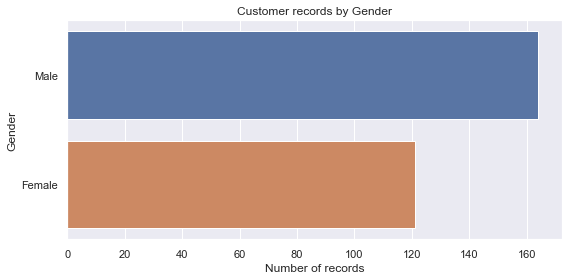

,count,percent
Marital Status,,
Single,189,66.3
Married,87,30.5
Prefer not to say,9,3.2


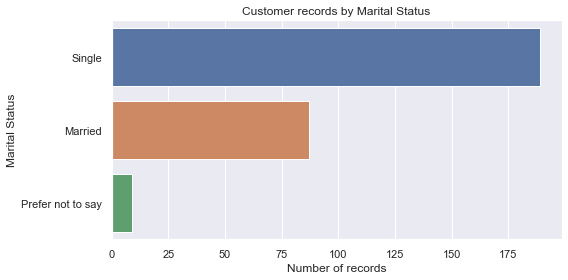

,count,percent
Occupation,,
Student,144,50.5
Employee,94,33.0
Self Employeed,38,13.3
House wife,9,3.2


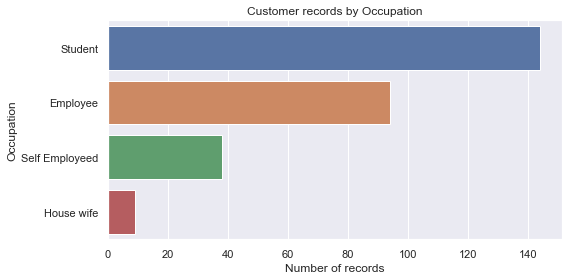

,count,percent
Monthly Income,,
No Income,131,46.0
25001 to 50000,52,18.2
More than 50000,47,16.5
10001 to 25000,36,12.6
Below Rs.10000,19,6.7


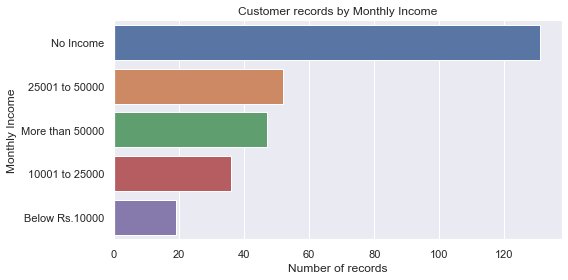

,count,percent
Educational Qualifications,,
Graduate,126,44.2
Post Graduate,125,43.9
Ph.D,21,7.4
School,11,3.9
Uneducated,2,0.7


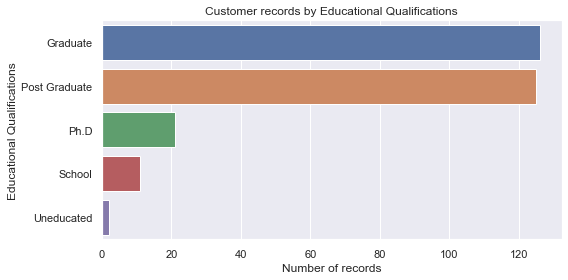

,count,percent
Customer Type,,
Regular,162,56.8
Frequent,105,36.8
New,18,6.3


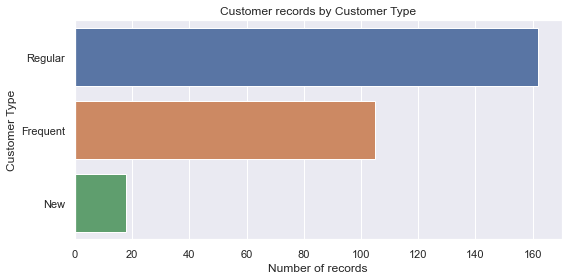

,count,percent
Feedback,,
Positive,231,81.1
Negative,54,18.9


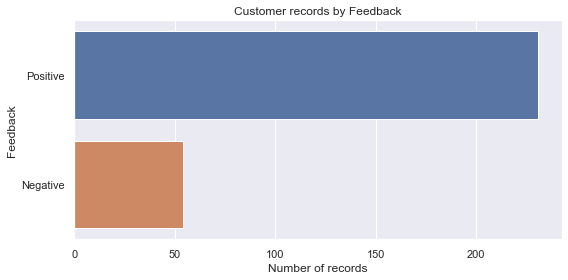

In [5]:
profile_cols = [
    "Gender", "Marital Status", "Occupation", "Monthly Income",
    "Educational Qualifications", "Customer Type", "Feedback"
]
profile_cols = [c for c in profile_cols if c in df_analysis.columns]

for col in profile_cols:
    counts = df_analysis[col].value_counts(dropna=False)
    display(counts.rename("count").to_frame().assign(
        percent=lambda x: (x["count"] / x["count"].sum() * 100).round(1)
    ))
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df_analysis, y=col, order=counts.index)
    plt.title(f"Customer records by {col}")
    plt.xlabel("Number of records")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

### 4.2 Age and family size

count    285.000000
mean      24.677193
std        3.040977
min       18.000000
25%       23.000000
50%       24.000000
75%       26.000000
max       33.000000
Name: Age, dtype: float64


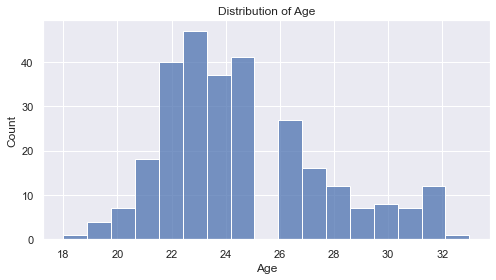

count    285.000000
mean       3.270175
std        1.361178
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        6.000000
Name: Family size, dtype: float64


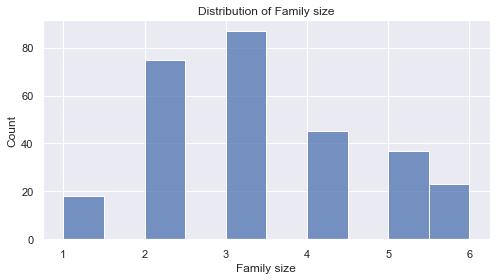

In [6]:
for col in ["Age", "Family size"]:
    if col in df_analysis.columns:
        print(df_analysis[col].describe())
        plt.figure(figsize=(7, 4))
        sns.histplot(data=df_analysis, x=col, bins="auto")
        plt.title(f"Distribution of {col}")
        plt.tight_layout()
        plt.show()

### 4.3 Feedback and customer type
Use row percentages to compare feedback patterns across customer types. Interpret small groups cautiously.

Feedback,Negative,Positive
Customer Type,,
Frequent,17.8,82.2
New,25.0,75.0
Regular,17.9,82.1


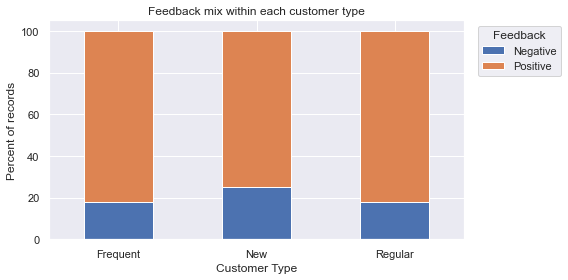

In [7]:
if {"Customer Type", "Feedback"}.issubset(df.columns):
    feedback_ct = pd.crosstab(df["Customer Type"], df["Feedback"], normalize="index") * 100
    display(feedback_ct.round(1))

    ax = feedback_ct.plot(kind="bar", stacked=True, figsize=(8, 4))
    ax.set_title("Feedback mix within each customer type")
    ax.set_ylabel("Percent of records")
    ax.set_xlabel("Customer Type")
    plt.xticks(rotation=0)
    plt.legend(title="Feedback", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

###   6. Explore Output by customer characteristics
These are descriptive comparisons, not causal effects.

Output mix within Gender (%)


Output,No,Yes
Gender,,
Female,25.6,74.4
Male,22.6,77.4


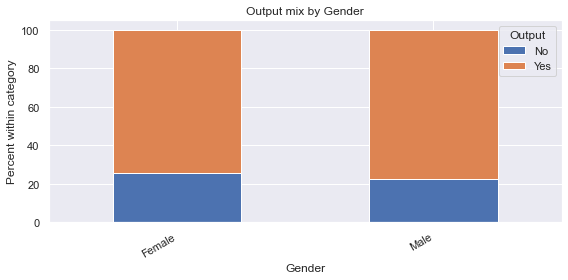

Output mix within Marital Status (%)


Output,No,Yes
Marital Status,,
Married,39.1,60.9
Prefer not to say,55.6,44.4
Single,15.3,84.7


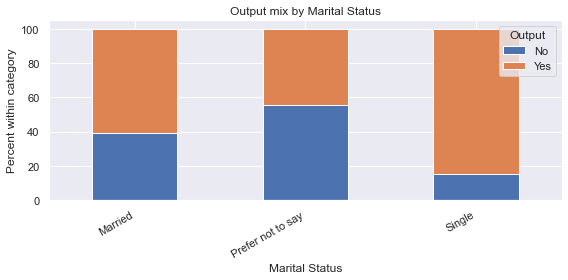

Output mix within Occupation (%)


Output,No,Yes
Occupation,,
Employee,36.2,63.8
House wife,22.2,77.8
Self Employeed,36.8,63.2
Student,12.5,87.5


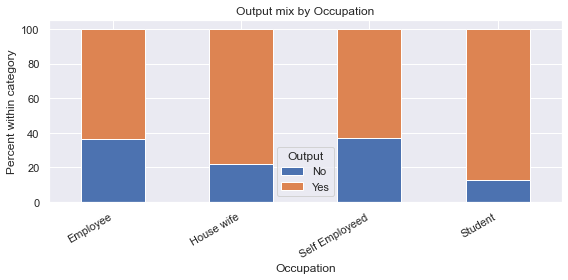

Output mix within Monthly Income (%)


Output,No,Yes
Monthly Income,,
10001 to 25000,25.0,75.0
25001 to 50000,36.5,63.5
Below Rs.10000,21.1,78.9
More than 50000,36.2,63.8
No Income,14.5,85.5


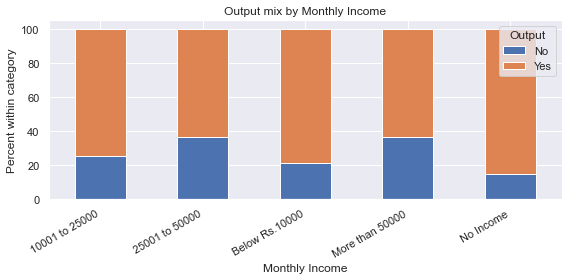

Output mix within Educational Qualifications (%)


Output,No,Yes
Educational Qualifications,,
Graduate,29.4,70.6
Ph.D,33.3,66.7
Post Graduate,16.8,83.2
School,18.2,81.8
Uneducated,50.0,50.0


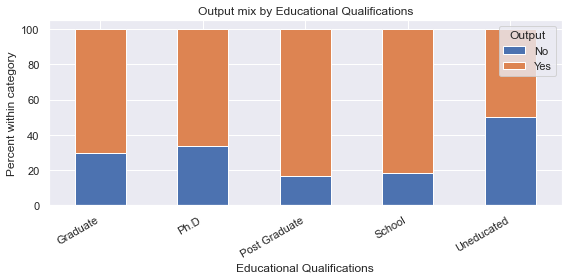

Output mix within Customer Type (%)


Output,No,Yes
Customer Type,,
Frequent,24.8,75.2
New,27.8,72.2
Regular,22.8,77.2


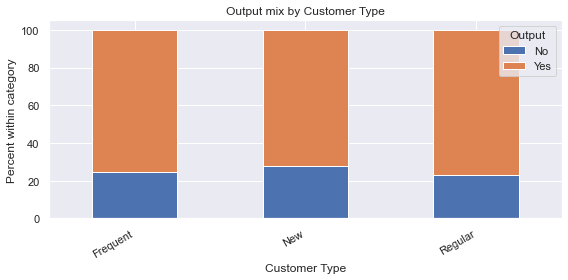

Output mix within Feedback (%)


Output,No,Yes
Feedback,,
Negative,72.2,27.8
Positive,12.6,87.4


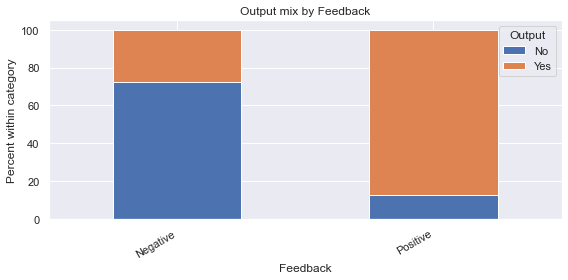

In [8]:
comparison_cols = [
    "Gender", "Marital Status", "Occupation", "Monthly Income",
    "Educational Qualifications", "Customer Type", "Feedback"
]
comparison_cols = [c for c in comparison_cols if c in df_analysis.columns]

for col in comparison_cols:
    tab = pd.crosstab(df_analysis[col], df_analysis["Output"], normalize="index") * 100
    print(f"Output mix within {col} (%)")
    display(tab.round(1))
    ax = tab.plot(kind="bar", stacked=True, figsize=(8, 4))
    ax.set_title(f"Output mix by {col}")
    ax.set_ylabel("Percent within category")
    ax.set_xlabel(col)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## 7. Feedback patterns by customer type
For categorical variables, a chi-square test can assess whether two variables are associated in this sample. Check expected cell counts; small samples can make the test unreliable.

Feedback,Negative,Positive
Customer Type,,
Frequent,19.0,81.0
New,22.2,77.8
Regular,18.5,81.5


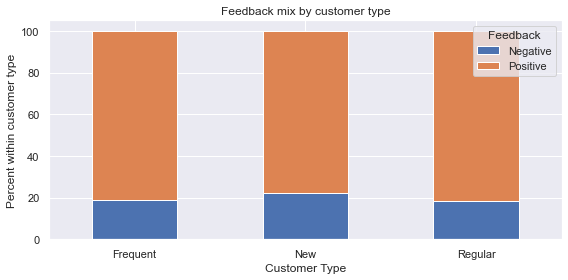

In [9]:
if {"Customer Type", "Feedback"}.issubset(df_analysis.columns):
    feedback_mix = pd.crosstab(
        df_analysis["Customer Type"], df_analysis["Feedback"], normalize="index"
    ) * 100
    display(feedback_mix.round(1))
    ax = feedback_mix.plot(kind="bar", stacked=True, figsize=(8, 4))
    ax.set_title("Feedback mix by customer type")
    ax.set_ylabel("Percent within customer type")
    ax.set_xlabel("Customer Type")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

 ## 8. Statistical association checks
A chi-square test can explore associations between categorical variables. Small expected counts make results less reliable, so inspect expected frequencies and treat p-values as exploratory rather than definitive.

In [10]:
from scipy.stats import chi2_contingency

for col in ["Gender", "Marital Status", "Occupation", "Monthly Income",
            "Educational Qualifications", "Customer Type", "Feedback"]:
    if col in df_analysis.columns:
        table = pd.crosstab(df_analysis[col], df_analysis["Output"])
        if table.shape[0] > 1 and table.shape[1] > 1:
            chi2, p, dof, expected = chi2_contingency(table)
            print(
                f"{col} vs Output | chi2={chi2:.3f} | dof={dof} | "
                f"p={p:.4f} | min expected cell={expected.min():.2f}"
            )

Gender vs Output | chi2=0.210 | dof=1 | p=0.6468 | min expected cell=28.87
Marital Status vs Output | chi2=23.616 | dof=2 | p=0.0000 | min expected cell=2.15
Occupation vs Output | chi2=21.609 | dof=3 | p=0.0001 | min expected cell=2.15
Monthly Income vs Output | chi2=14.942 | dof=4 | p=0.0048 | min expected cell=4.53
Educational Qualifications vs Output | chi2=7.516 | dof=4 | p=0.1110 | min expected cell=0.48
Customer Type vs Output | chi2=0.292 | dof=2 | p=0.8642 | min expected cell=4.29
Feedback vs Output | chi2=82.523 | dof=1 | p=0.0000 | min expected cell=12.88


## 9. Business insights — complete after reviewing outputs
For each insight, write: Observation → Evidence → Business implication → Caveat. Only include conclusions supported by the charts and tables. Avoid causal claims.

## 10. Machine learning decision gate
Before training a model, confirm what Output means and when it is recorded. Do not include the duplicate target column, and do not automatically use Feedback or Customer Type as predictors until their timing and relationship to the target are understood. With only 285 unique rows after exact-deduplication, performance estimates may be unstable. If the target meaning is unclear, finish a high-quality EDA project rather than forcing a predictive model.model prospectively.

# Customer Profile & Target Analysis

## 11. Customer Profile Overview

This section explores the demographic characteristics of customers,
including age, gender, occupation, and marital status.

The objective is to understand the composition of the dataset
before investigating customer ordering behavior.

# Cell 2 — Distribution of Customer Demographics

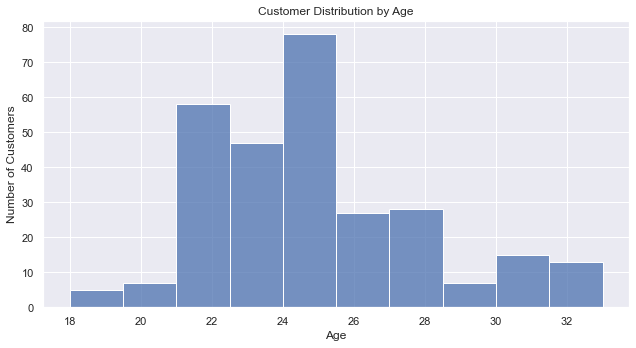

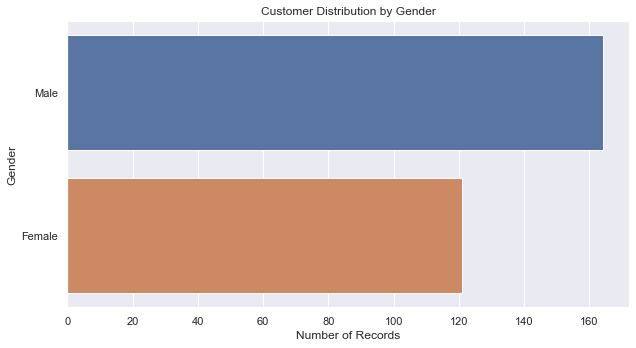

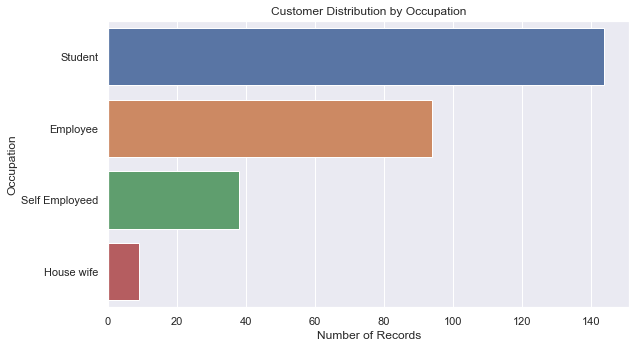

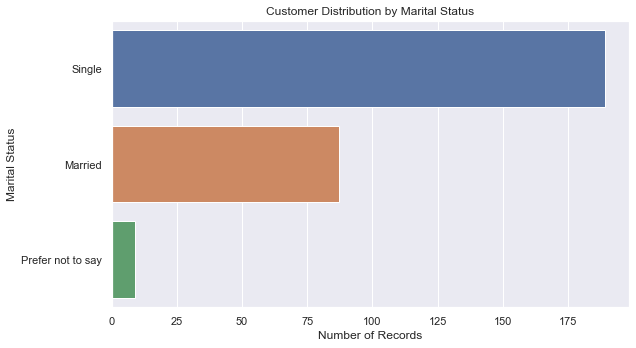

In [11]:
# Distribution of Customer Demographics

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

# Define demographic columns
demographic_columns = [
    "Age",
    "Gender",
    "Occupation",
    "Marital Status"
]

# Create a separate chart for each variable
for column in demographic_columns:

    plt.figure(figsize=(9, 5))

    if column == "Age":

        sns.histplot(
            data=df_analysis,
            x=column,
            bins=10
        )

    else:

        order = df_analysis[column].value_counts().index

        sns.countplot(
            data=df_analysis,
            y=column,
            order=order
        )

    plt.title(f"Customer Distribution by {column}")
    plt.xlabel("Number of Records" if column != "Age" else "Age")
    plt.ylabel("Number of Customers" if column == "Age" else column)

    plt.tight_layout()
    plt.show()

# Cell 3 — Distribution of Online Food Ordering Behavior

## 12. Distribution of Online Food Ordering Behavior

This section examines the distribution of the target variable, Output.

The objective is to understand the balance between the Yes and No
categories before conducting further analysis or building a
machine learning model.

,Count,Percentage
Output,,
Yes,217,76.14
No,68,23.86


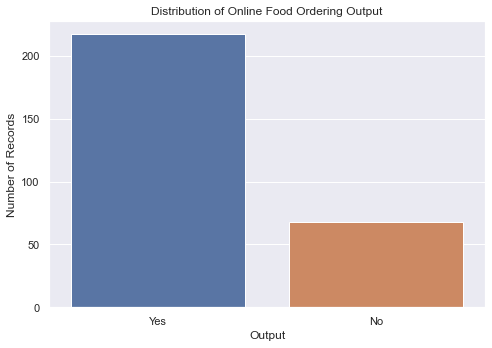

In [12]:
# Distribution of Online Food Ordering Behavior

output_counts = df_analysis["Output"].value_counts()

output_percentages = (
    df_analysis["Output"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

output_summary = pd.DataFrame({
    "Count": output_counts,
    "Percentage": output_percentages
})

display(output_summary)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_analysis,
    x="Output",
    order=["Yes", "No"]
)

plt.title("Distribution of Online Food Ordering Output")
plt.xlabel("Output")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

# ## 13. Customer Characteristics vs. Ordering Behavior

Analyze how online food ordering behavior varies across different customer characteristics.

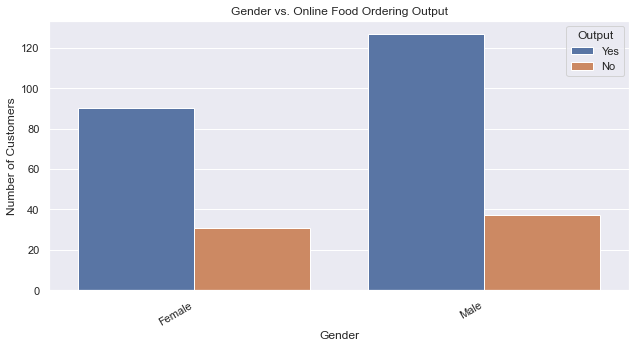

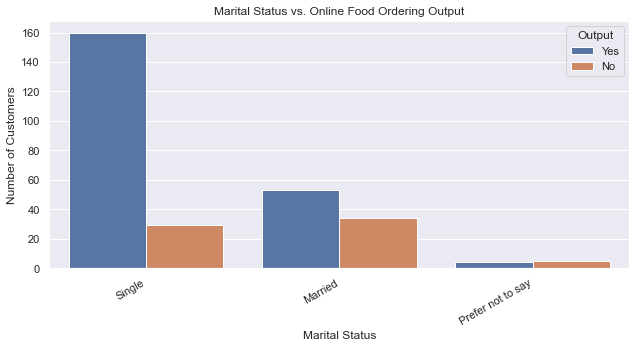

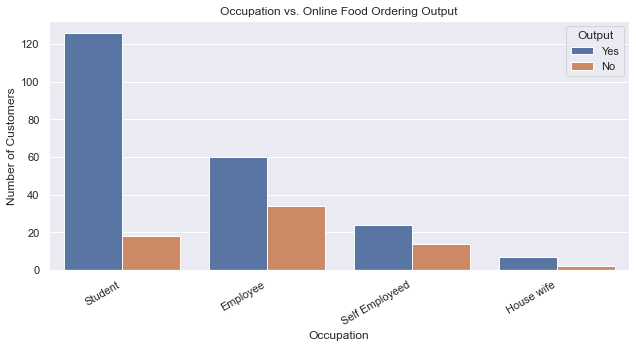

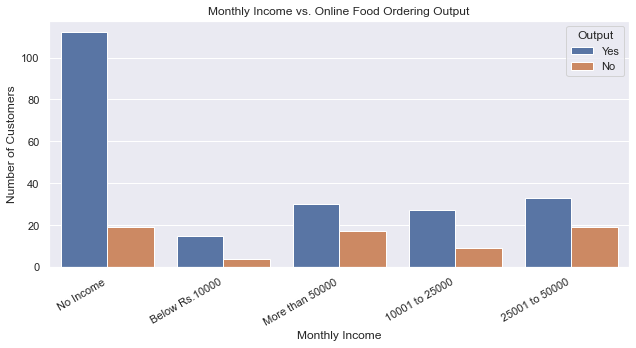

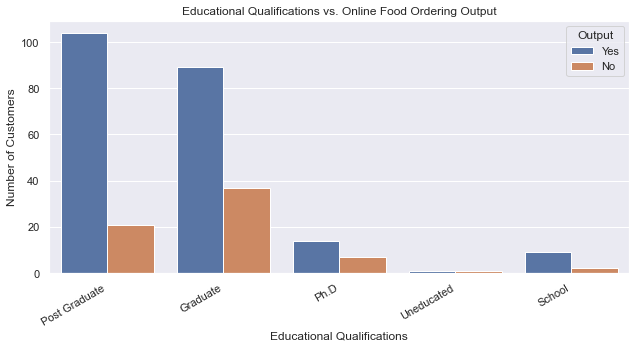

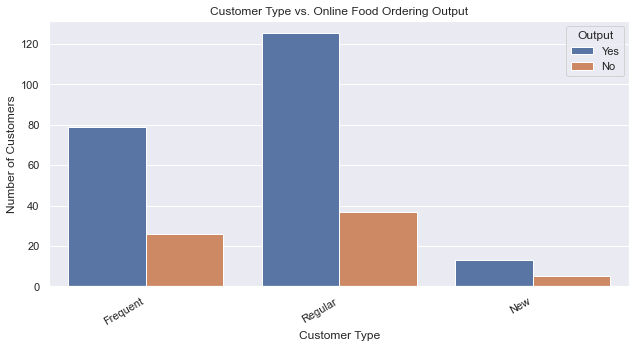

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select customer characteristics to analyze
features = [
    "Gender",
    "Marital Status",
    "Occupation",
    "Monthly Income",
    "Educational Qualifications",
    "Customer Type"
]

# Plot each feature against ordering output
for feature in features:
    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df_analysis,
        x=feature,
        hue="Output"
    )

    plt.title(f"{feature} vs. Online Food Ordering Output")
    plt.xlabel(feature)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

### 14 Ordering Rate by Gender

Output,No,Yes
Gender,,
Female,25.62,74.38
Male,22.56,77.44


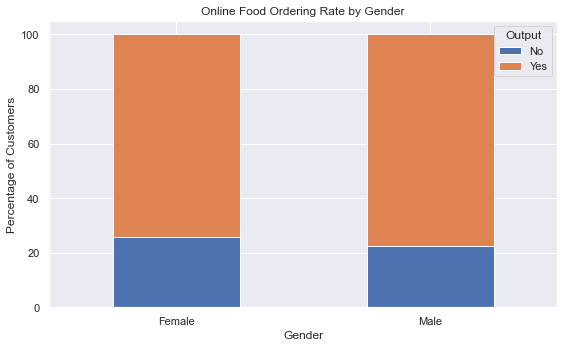

In [14]:
gender_ordering_rate = pd.crosstab(
    df_analysis["Gender"],
    df_analysis["Output"],
    normalize="index"
) * 100

gender_ordering_rate = gender_ordering_rate.round(2)

display(gender_ordering_rate)

gender_ordering_rate.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Online Food Ordering Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage of Customers")
plt.legend(title="Output")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 15 Ordering Rate by Marital Status

Output,No,Yes
Marital Status,,
Married,39.08,60.92
Prefer not to say,55.56,44.44
Single,15.34,84.66


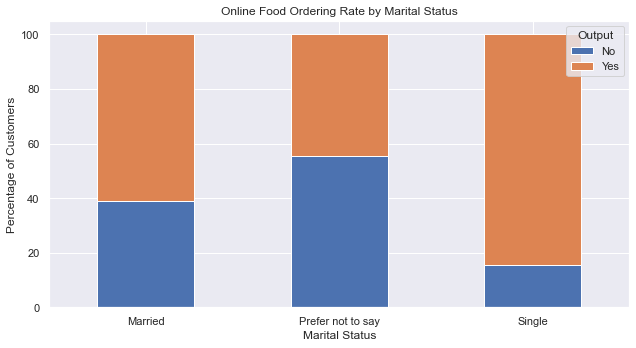

In [15]:
marital_ordering_rate = pd.crosstab(
    df_analysis["Marital Status"],
    df_analysis["Output"],
    normalize="index"
) * 100

marital_ordering_rate = marital_ordering_rate.round(2)

display(marital_ordering_rate)

marital_ordering_rate.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Online Food Ordering Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Percentage of Customers")
plt.legend(title="Output")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 16 Ordering Rate by Occupation

Output,No,Yes
Occupation,,
Employee,36.17,63.83
House wife,22.22,77.78
Self Employeed,36.84,63.16
Student,12.50,87.50


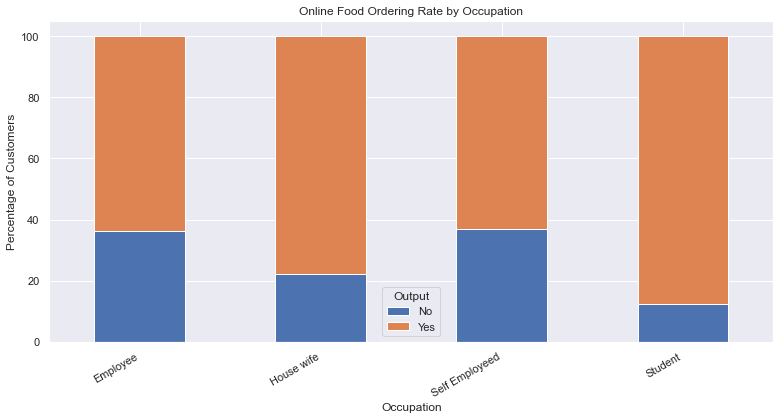

In [16]:
occupation_ordering_rate = pd.crosstab(
    df_analysis["Occupation"],
    df_analysis["Output"],
    normalize="index"
) * 100

occupation_ordering_rate = occupation_ordering_rate.round(2)

display(occupation_ordering_rate)

occupation_ordering_rate.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Online Food Ordering Rate by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Percentage of Customers")
plt.legend(title="Output")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()